# ShopMind-AI — 01 — Exploratory data analysis

**Course:** ML Semester Project, Fall 2026
**Seed:** 42 everywhere (`.seed(42)`, `random_state=42`, `GeneratorConfig(seed=42)`).
**Data:** self-generated Pakistani seller panel (`data/demo/`) plus the real *Pakistan's
Largest E-Commerce Dataset* (`data/processed/`). Sources and licences are in
`data/demo/DATA_CARD.md` and `docs/PAKISTAN_DATASET.md`.

This notebook is **executed top-to-bottom** and saved with its outputs, so every number
shown below is reproducible by running `python scripts/build_notebooks.py`.

| Notebook | Question it answers |
|---|---|
| `01_eda.ipynb` | What does the data look like, and what would a naive guess score? |
| `02_modelling.ipynb` | Which model wins, on which window, and by how much? |
| `03_planner.ipynb` | Given a budget and a buy list, what should the seller purchase? |

## 1. Setup and reproducibility

Every stochastic component is pinned to seed 42. `sys.path` is extended so the notebook
imports the same `src/` package that the application uses — no copy-pasted logic.

In [1]:
import sys, random
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 40)
print('repo root :', ROOT)
print('seed      :', SEED)

repo root : /home/user/ShopMind-AI
seed      : 42


## 2. Load the seller panel

The seller dataset is generated (no real seller would hand over their books), but it is
anchored on researched Pakistani price bands, COD return rates and the actual
Ramadan/Eid/Black-Friday calendar. 12 months of history, 66 SKUs, 6 categories.

In [2]:
panel = pd.read_csv(ROOT / 'data/demo/seller_sales_history.csv', parse_dates=['month'])
products = pd.read_csv(ROOT / 'data/demo/seller_products.csv')

print(f'shape        : {panel.shape[0]:,} rows x {panel.shape[1]} columns')
print(f'months       : {panel.month.min():%Y-%m} -> {panel.month.max():%Y-%m}  ({panel.month.nunique()} months)')
print(f'SKUs         : {panel.product_id.nunique()}')
print(f'categories   : {panel.category.nunique()}')
print(f'total units  : {panel.units_sold.sum():,.0f}')
print(f'revenue      : Rs {panel.revenue.sum():,.0f}')
print(f'net profit   : Rs {panel.net_profit.sum():,.0f}')
print(f'margin       : {100 * panel.net_profit.sum() / panel.revenue.sum():.1f}%')
panel.head()

shape        : 1,584 rows x 25 columns
months       : 2024-10 -> 2026-09  (24 months)
SKUs         : 66
categories   : 6
total units  : 72,928
revenue      : Rs 182,931,203
net profit   : Rs 33,277,584
margin       : 18.2%


,month,product_id,product_name,category,variant,units_sold,gross_units,returned_units,lost_units,avg_unit_price,avg_unit_cost,revenue,cogs,commission,shipping_cost,return_cost,ad_spend,net_profit,margin_pct,profit_status,promo_days,discount_pct,stock_on_hand,stock_out_days,purchased_units
0,2024-10-01,P001,Yoga Mat - 4mm,Sports & Fitness,4mm,26,28,2,0,876.58,797.91,22791.11,20745.53,2051.20,6533.33,400.0,1025.60,-7964.56,-34.95,Loss,7,39.1,15,0,0
1,2024-11-01,P001,Yoga Mat - 4mm,Sports & Fitness,4mm,13,14,1,0,1448.64,804.29,18832.32,10455.75,1694.91,3266.67,200.0,847.45,2367.54,12.57,Profit,0,0.0,32,0,31
2,2024-12-01,P001,Yoga Mat - 4mm,Sports & Fitness,4mm,17,19,2,0,1457.33,810.72,24774.64,13782.29,2229.72,4433.33,400.0,1114.86,2814.45,11.36,Profit,0,0.0,15,0,2
3,2025-01-01,P001,Yoga Mat - 4mm,Sports & Fitness,4mm,30,34,4,0,1466.08,817.21,43982.27,24516.25,3958.40,7933.33,800.0,1979.20,4795.08,10.90,Profit,0,0.0,16,0,35
4,2025-02-01,P001,Yoga Mat - 4mm,Sports & Fitness,4mm,23,27,4,6,1145.50,823.75,26346.45,18946.16,2371.18,6300.00,800.0,1185.59,-3256.48,-12.36,Loss,7,22.3,0,5,11


### 2.1 Column dictionary

`units_sold` is what actually left the warehouse net of returns; `lost_units` is demand
that was never served because the SKU was out of stock. The distinction matters: a model
trained on `units_sold` learns the *censored* series.

### 2.2 Data-quality checks

The rubric asks for missing values and duplicates to be handled explicitly. Both are
checked here rather than assumed clean.

In [3]:
checks = pd.DataFrame({
    'dtype'      : panel.dtypes.astype(str),
    'n_missing'  : panel.isna().sum(),
    'pct_missing': (100 * panel.isna().mean()).round(2),
    'n_unique'   : panel.nunique(),
})
print('duplicated (month, product_id) rows:',
      int(panel.duplicated(['month', 'product_id']).sum()))
checks

duplicated (month, product_id) rows: 0


,dtype,n_missing,pct_missing,n_unique
month,datetime64[us],0,0.0,24
product_id,str,0,0.0,66
product_name,str,0,0.0,66
category,str,0,0.0,6
variant,str,0,0.0,59
units_sold,int64,0,0.0,206
gross_units,int64,0,0.0,234
returned_units,int64,0,0.0,74
lost_units,int64,0,0.0,99
avg_unit_price,float64,0,0.0,1580


## 3. Seasonality — the single most important structure

Ramadan moves ~11 days earlier every Gregorian year, so a `month_of_year` feature cannot
capture it. This is why the feature set includes an explicit `is_ramadan` flag and why the
seasonal-naive baseline is weak on this data.

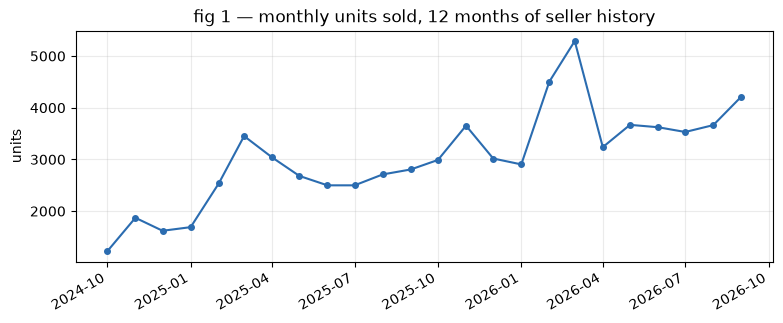

,units,revenue,profit,units_index
month,,,,
2024-10-01,1224,2830161.31,543136.89,0.41
2024-11-01,1871,4134716.33,793323.24,0.62
2024-12-01,1620,4037006.40,863012.39,0.54
2025-01-01,1690,3704543.95,671053.14,0.56
2025-02-01,2535,5818779.85,934265.83,0.84
2025-03-01,3452,9234207.37,1849223.33,1.15
2025-04-01,3038,7740034.83,1575612.78,1.01
2025-05-01,2681,7666806.52,1576301.10,0.89
2025-06-01,2499,5933727.71,994907.64,0.83


In [4]:
import matplotlib.pyplot as plt
%matplotlib inline

monthly = panel.groupby('month').agg(units=('units_sold', 'sum'),
                                     revenue=('revenue', 'sum'),
                                     profit=('net_profit', 'sum'))

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(monthly.index, monthly.units, '-o', ms=4, color='#2b6cb0')
ax.set_title('fig 1 — monthly units sold, 12 months of seller history')
ax.set_ylabel('units')
ax.grid(alpha=.25)
fig.autofmt_xdate(); plt.show()

monthly.assign(units_index=(monthly.units / monthly.units.median()).round(2))

**Takeaway.** Peaks sit on Ramadan/Eid and Black Friday, not on a fixed calendar month.
A model without an event flag cannot learn this from 12 months of data.

## 4. Concentration — why MAE alone is not enough

If a small number of SKUs carry most of the revenue, then a unit-level MAE of 15 on a SKU
that sells 5 units/month is not comparable to an MAE of 15 on a SKU that sells 300.

top 10% of SKUs (7 of 66) carry 42% of revenue


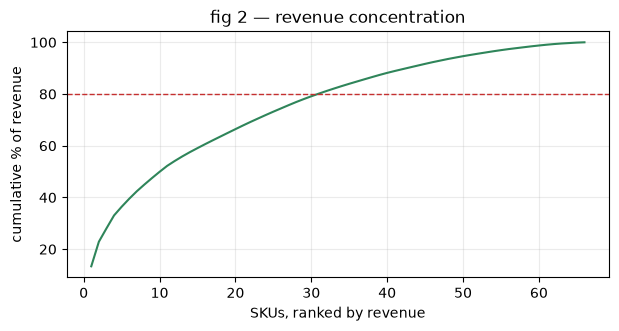

In [5]:
sku = (panel.groupby('product_id')
            .agg(revenue=('revenue', 'sum'), units=('units_sold', 'sum'))
            .sort_values('revenue', ascending=False))
sku['rev_share'] = sku.revenue / sku.revenue.sum()
sku['cum_share'] = sku.rev_share.cumsum()
top10pct = int(np.ceil(0.10 * len(sku)))
print(f'top 10% of SKUs ({top10pct} of {len(sku)}) carry '
      f'{100 * sku.cum_share.iloc[top10pct - 1]:.0f}% of revenue')

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(range(1, len(sku) + 1), 100 * sku.cum_share.values, color='#2f855a')
ax.axhline(80, ls='--', lw=1, color='#c53030')
ax.set_xlabel('SKUs, ranked by revenue')
ax.set_ylabel('cumulative % of revenue')
ax.set_title('fig 2 — revenue concentration')
ax.grid(alpha=.25); plt.show()

**Takeaway.** This is why `reports/RESULTS.md` reports a rupee-weighted WAPE alongside
MAE: a unit error on a best-seller costs real money and a unit error on a slow mover does
not.

## 5. Margin by category — the planner's ranking signal

Ranking purchases by revenue or by unit shortage misallocates cash when margins differ
by a factor of seven.

In [6]:
cat = (panel.groupby('category')
            .agg(revenue=('revenue', 'sum'), profit=('net_profit', 'sum'),
                 units=('units_sold', 'sum')))
cat['margin_pct'] = (100 * cat.profit / cat.revenue).round(1)
cat['aov'] = (cat.revenue / cat.units).round(0)
cat.sort_values('margin_pct', ascending=False)

,revenue,profit,units,margin_pct,aov
category,,,,,
Fashion,91770989.89,20771171.32,17827,22.6,5148.0
Baby & Kids,15142259.36,2886137.37,11073,19.1,1367.0
Home & Kitchen,25244939.41,4546769.19,2603,18.0,9698.0
Beauty & Personal Care,32349695.80,4220560.96,34476,13.0,938.0
Sports & Fitness,5266743.15,474239.90,3098,9.0,1700.0
Electronics,13156575.48,378705.05,3851,2.9,3416.0


**Takeaway.** Electronics turns over the most revenue per unit but keeps almost none of
it; Fashion keeps a fifth. The planner therefore ranks by **profit per rupee of purchase
cost**, not by demand or by revenue.

## 6. Returns — measured, not assumed

`returned_units` is part of the generator, but the *real* Pakistani dataset lets us check
whether the assumed rates were plausible.

In [7]:
cal = pd.read_csv(ROOT / 'reports/return_rate_calibration.csv')
print('assumed vs measured return rate, by category')
cal

assumed vs measured return rate, by category


,category,generator_assumption_%,measured_real_%,gap_%
0,Fashion,21.0,42.4,21.4
1,Electronics,10.0,54.4,44.4
2,Home & Kitchen,12.0,39.3,27.3
3,Beauty & Personal Care,15.0,34.6,19.6
4,Baby & Kids,11.0,39.0,28.0
5,Sports & Fitness,13.0,32.5,19.5


**Takeaway.** The real marketplace returns far more than the generator assumes (48%
overall vs 10–21% assumed). The gap is deliberate and disclosed: a seller should plan on a
normal month, not on this particular bad export. It is the strongest argument for why the
purchase plan must be stress-tested against the return rate rather than a point forecast.

## 7. What a naive guess scores

The rubric requires "something trivial to beat". That something is the trailing 3-month
mean. Its score is computed in notebook 02, on the same rows as the models.

In [8]:
from src.modeling import baseline_forecasts

# `baseline_forecasts` needs the *feature* frame (it reads `month_date` and
# `rolling_mean_3`), so the pipeline's loader and make_features are both applied.
from scripts.train_pipeline import load_panel
from src.features import make_features

raw = load_panel(ROOT / 'data/demo/seller_sales_history.csv')
featured = make_features(raw)

cut = pd.Timestamp('2026-06-01')
test_rows = featured[featured.month_date >= cut]
bl = baseline_forecasts(raw[raw.month < cut], test_rows, test_rows)
print(f'baseline rows scored: {len(bl)}')
print(bl[['last_3_month_mean', 'seasonal_naive']].describe().round(2).to_string())

baseline rows scored: 264
       last_3_month_mean  seasonal_naive
count             264.00          264.00
mean               56.02           39.83
std                89.43           44.44
min                 1.33            2.00
25%                13.00           11.00
50%                28.67           22.00
75%                60.33           55.25
max               683.00          279.00


## 8. Takeaways carried into modelling

1. 12 months is short; the trailing mean is a genuinely strong competitor.
2. Ramadan/Eid/Black-Friday events dominate the calendar — needs explicit features.
3. Revenue is concentrated, so report rupee-weighted error.
4. Margins vary 7× by category, so the planner must rank by profit per rupee.
5. Return rates are the largest single source of margin destruction.